## Running Utility Model

In [ ]:
# importing necessary libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Senior Year/Spring 2026/EC 410/State Park Project/Spreadsheet List of All counties in North Carolina export 2026-03-24 04-37-17.csv")

In [ ]:
df.head()

,name,name_ascii,type,county_fips,state_id,state_name,lat,lng,population
0,Yancey,Yancey,County,37199,NC,North Carolina,35.8989,-82.3076,18357
1,Yadkin,Yadkin,County,37197,NC,North Carolina,36.1605,-80.6652,37198
2,Wilson,Wilson,County,37195,NC,North Carolina,35.7051,-77.9187,78844
3,Wilkes,Wilkes,County,37193,NC,North Carolina,36.2062,-81.1630,66335
4,Wayne,Wayne,County,37191,NC,North Carolina,35.3640,-78.0040,117692


In [ ]:
park_coords = [34.331944, -78.0325]

In [ ]:
from geopy.distance import geodesic

def compute_distance(row):
    return geodesic((row["lat"], row["lng"]), park_coords).miles

df["distance_miles"] = df.apply(compute_distance, axis=1)

In [ ]:
speed = 50        # mph
wage = 25         # $/hour NC 2020 estimate
time_fraction = 0.4

df["time_hours"] = df["distance_miles"] / speed
df["time_cost"] = df["time_hours"] * wage * time_fraction
df["mileage_cost"] = df["distance_miles"] * 0.575 #IRS 2020 estimate

df["travel_cost"] = df["time_cost"] + df["mileage_cost"]

In [ ]:
visitor_by_acreage = 165000/2778
total_visits = visitor_by_acreage*3400
print(total_visits)

201943.8444924406


In [ ]:
df["weight"] = df["population"] / df["travel_cost"]
df["visits"] = total_visits * (df["weight"] / df["weight"].sum())

In [ ]:
df["non_visits"] = df["population"] - df["visits"]

In [ ]:
import statsmodels.api as sm

X = sm.add_constant(df["travel_cost"])
y = df[["visits", "non_visits"]]

model = sm.GLM(y, X, family=sm.families.Binomial())
results = model.fit()

print(results.summary())

                    Generalized Linear Model Regression Results                     
Dep. Variable:     ['visits', 'non_visits']   No. Observations:                  100
Model:                                  GLM   Df Residuals:                       98
Model Family:                      Binomial   Df Model:                            1
Link Function:                        Logit   Scale:                          1.0000
Method:                                IRLS   Log-Likelihood:                -17697.
Date:                      Wed, 01 Apr 2026   Deviance:                       34554.
Time:                              05:08:10   Pearson chi2:                 4.16e+04
No. Iterations:                           8   Pseudo R-squ. (CS):              1.000
Covariance Type:                  nonrobust                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------

In [ ]:
import numpy as np

alpha = results.params["const"]
beta = results.params["travel_cost"]

df["CV"] = (-1 / beta) * np.log(1 + np.exp(alpha - beta * df["travel_cost"]))

In [ ]:
total_WTP = (df["CV"] * df["population"]).sum()
print(total_WTP)

404333881.7565272


In [ ]:
#WTP per person
WTP = total_WTP / df["population"].sum()
print(WTP)

39.00193148587195


In [ ]:
print(beta)

-0.01886027700057689


In [ ]:
import numpy as np

# --- INPUTS ---
capital_cost_2018 = np.array([4666500, 6566500])  # 2018$
inflation_rate = 0.02  # approx annual inflation from 2018 to 2020
operating_5yr = np.array([3412000, 6117000])     # 5-year cumulative operating cost

park_life = 30          # years
annual_visitors = 165000  # example estimate
discount_rate = 0.03     # 3% social discount rate

# --- STEP 1: Take medians ---
capital_median = np.median(capital_cost_2018)
operating_median = np.median(operating_5yr)

# --- STEP 2: Adjust capital cost to 2020 dollars ---
capital_2020 = capital_median * (1 + inflation_rate)**2

# --- STEP 3: Annualize capital cost ---
annual_capital_cost = capital_2020 / park_life

# --- STEP 4: Annual operating cost ---
annual_operating_cost = operating_median / 5  # average over 5 years

# --- STEP 5: Total annual cost ---
annual_total_cost = annual_capital_cost + annual_operating_cost

# --- STEP 6: Marginal cost per visitor ---
mc_per_visitor = annual_total_cost / annual_visitors

# --- STEP 7 (Optional): Present value over 30 years ---
years = np.arange(1, park_life + 1)
pv_total_cost = sum(annual_total_cost / (1 + discount_rate)**years)

# --- OUTPUT ---
print("Annual Capital Cost (2020$):", round(annual_capital_cost, 2))
print("Annual Operating Cost (2020$):", round(annual_operating_cost, 2))
print("Annual Total Cost (2020$):", round(annual_total_cost, 2))
print(f"Marginal Cost per Visitor ($): {round(mc_per_visitor, 2)}")
print("Present Value of 30-Year Costs (2020$):", round(pv_total_cost, 2))

Annual Capital Cost (2020$): 194780.22
Annual Operating Cost (2020$): 952900.0
Annual Total Cost (2020$): 1147680.22
Marginal Cost per Visitor ($): 6.96
Present Value of 30-Year Costs (2020$): 22495038.84


## Creating Visualization

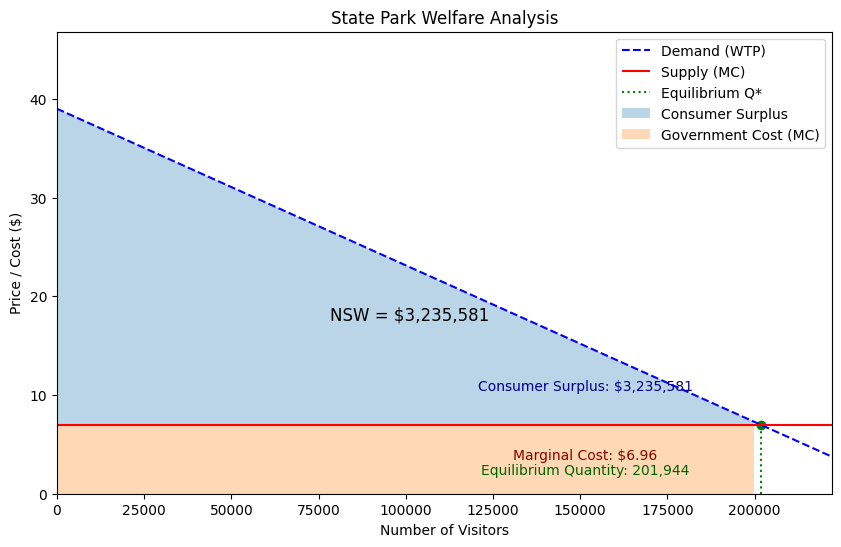

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# setting parameters
WTP = round(WTP)      # choke price (max willingness to pay)
MC = mc_per_visitor       # marginal cost
Q_post = df["visits"].sum()   # equilibrium quantity

# --- creating demand curve
Q_vals = np.linspace(0, Q_post*1.1, 100)

# solve for slope
b = (WTP - MC) / Q_post
P_demand = WTP - b * Q_vals

# creating graph
plt.figure(figsize=(10,6))

# displaying demand curve (WTP)
plt.plot(Q_vals, P_demand, color='blue', linestyle='--', label='Demand (WTP)')

# displaying supply curve (MC)
plt.hlines(MC, 0, Q_post*1.1, colors='red', linestyles='-', label='Supply (MC)')

# Equilibrium point
plt.scatter(Q_post, MC, color='green')
plt.vlines(Q_post, 0, MC, colors='green', linestyles=':', label='Equilibrium Q*')

# Consumer surplus
CS = 0.5 * (WTP - MC) * Q_post # Calculate Consumer Surplus
plt.fill_between(
    Q_vals[Q_vals <= Q_post],
    MC,
    P_demand[Q_vals <= Q_post],
    alpha=0.3,
    label='Consumer Surplus'
)

# Government cost
plt.fill_between(
    Q_vals[Q_vals <= Q_post],
    0,
    MC,
    alpha=0.3,
    label='Government Cost (MC)'
)

# graph labels
plt.xlabel('Number of Visitors')
plt.ylabel('Price / Cost ($)')
plt.title('State Park Welfare Analysis')

plt.xlim(0, Q_post*1.1)
plt.ylim(0, WTP*1.2)

plt.legend()

# net social welfare
NSW = 0.5 * (WTP - MC) * Q_post
plt.text(Q_post*0.5, MC + (WTP-MC)/3,
         f'NSW = ${NSW:,.0f}',
         fontsize=12, ha='center')

# displaying values
plt.text(Q_post * 0.75, MC * 1.5,
         f'Consumer Surplus: ${CS:,.0f}',
         fontsize=10, ha='center', color='darkblue')
plt.text(Q_post * 0.75, MC * 0.5,
         f'Marginal Cost: ${MC:,.2f}',
         fontsize=10, ha='center', color='darkred')
plt.text(Q_post * 0.75, WTP * 0.05,
         f'Equilibrium Quantity: {Q_post:,.0f}',
         fontsize=10, ha='center', color='darkgreen')

plt.savefig('welfare_graph.png')
plt.show()

In [ ]:
new_WTP = WTP - 5
new_NSW = 0.5 * (new_WTP - MC) * Q_post
print(f"New Net Social Welfare with $5 entrance fee: ${new_NSW:,.2f}")

New Net Social Welfare with $5 entrance fee: $2,730,721.25


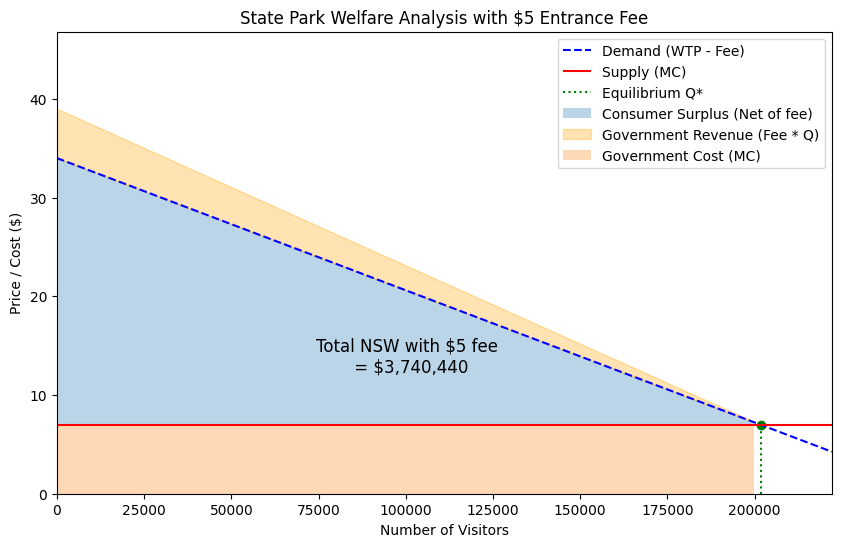

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# setting paramaters
# Using the previously calculated new_WTP and MC
# WTP is the original WTP for consistent y-axis scaling, new_WTP is used for demand curve
MC = mc_per_visitor
Q_post = df["visits"].sum()

# creating demand curve
Q_vals = np.linspace(0, Q_post*1.1, 100)

# solving for slope
b_new = (new_WTP - MC) / Q_post
P_demand_new = new_WTP - b_new * Q_vals

# calculating original demand curve
b_original = (WTP - MC) / Q_post
P_demand_original = WTP - b_original * Q_vals

# creating figure
plt.figure(figsize=(10,6))

# Demand curve with $3 fee
plt.plot(Q_vals, P_demand_new, color='blue', linestyle='--', label='Demand (WTP - Fee)')

# Supply curve (MC)
plt.hlines(MC, 0, Q_post*1.1, colors='red', linestyles='-', label='Supply (MC)')

# Equilibrium point
plt.scatter(Q_post, MC, color='green')
plt.vlines(Q_post, 0, MC, colors='green', linestyles=':', label='Equilibrium Q*')

# Consumer surplus with the new WTP
plt.fill_between(
    Q_vals[Q_vals <= Q_post],
    MC,
    P_demand_new[Q_vals <= Q_post],
    alpha=0.3,
    label='Consumer Surplus (Net of fee)'
)

# Government revenue
plt.fill_between(
    Q_vals[Q_vals <= Q_post],
    P_demand_new[Q_vals <= Q_post],
    P_demand_original[Q_vals <= Q_post],
    alpha=0.3,
    color='orange',
    label='Government Revenue (Fee * Q)'
)

# Government cost
plt.fill_between(
    Q_vals[Q_vals <= Q_post],
    0,
    MC,
    alpha=0.3,
    label='Government Cost (MC)'
)

#graph labels
plt.xlabel('Number of Visitors')
plt.ylabel('Price / Cost ($)')
plt.title('State Park Welfare Analysis with $5 Entrance Fee')

plt.xlim(0, Q_post*1.1)
plt.ylim(0, WTP*1.2)

plt.legend()

# Net social welfare including govt revenue
total_NSW_with_revenue = new_NSW + (5 * Q_post)
plt.text(Q_post*0.5, MC + (new_WTP-MC)/5,
         f'Total NSW with $5 fee \n = ${total_NSW_with_revenue:,.0f}',
         fontsize=12, ha='center')

plt.savefig('welfare_graph_with_5_dollar_fee.png')
plt.show()